## Machine Learning Notebook Week-4

### Table of Contents

##### 1. Unsupervised Learning 
##### 2. Clustering (K-Means / Heirarchichal / DBSCAN) 
##### 3. Clsuter Evaluation Metrics (Elbow Plot / Dendrogram / Silhouette Score)
##### 4. Dimensionality Reduction Techniques 
##### 5. Principal Component Analysis
##### 6. Association Rules
##### 7. Recommendation Engines

### Unsupervised learning 

Unsupervised Learning is a type of machine learning where the model is trained on an unlabeled dataset. The system tries to identify hidden structures or patterns in the data without predefined output labels, often through techniques like clustering or dimensionality reduction.

In short in supervised learning we dont have Target Varible.

##### Clsutering 

Clustering is an unsupervised learning technique used to group similar data points into clusters based on their characteristics or patterns — without using any predefined labels.
The goal is to ensure that data points in the same cluster are more similar to each other than to those in other clusters.

In simple words:
Clustering means grouping similar things together automatically based on their features.

Examples:

Grouping customers with similar buying behavior.

Organizing news articles by topic.

####  Data Definition (Customer finance data)

Here's a brief version of what you'll find in the data

**Cust_Number**: Unique customer identification number

**Yearly_Income**: Annual income of the customer

**Age**: Age of the customer

**Cust_Spend_Score**: Spending score of the customer

**Sex**: Gender of the customer (0 = male, 1 = female)

In [16]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')


In [17]:
df = pd.read_csv('customer.csv')

In [18]:
# consider the features 'Cust_Spend_Score' and 'Yearly_Income'
cluster_data = df[['Cust_Spend_Score', 'Yearly_Income']]

# print top 5 observations of X
cluster_data.head()

,Cust_Spend_Score,Yearly_Income
0,44,15000
1,79,15000
2,8,16000
3,79,16000
4,41,17000


In [19]:
# initialize the StandardScaler
from sklearn.preprocessing import StandardScaler
SS = StandardScaler()
x_scaled = SS.fit_transform(cluster_data)
X = pd.DataFrame(x_scaled, columns = cluster_data.columns)
X.head(2)

,Cust_Spend_Score,Yearly_Income
0,-0.284181,-1.738999
1,1.063563,-1.738999


#### K- Means Clsutering

Definition:
K-Means is a centroid-based clustering algorithm that divides the data into K distinct clusters.
It works by assigning each data point to the nearest cluster center (centroid) and then updating the centroids until they stabilize.

In simple words:
K-Means groups data into K clusters by finding the best center points (means) for each cluster.

##### K-Means Model

In [20]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [21]:
kmeans = KMeans(n_clusters = 3, random_state = 10)
kmeans.fit(X)
kmeans.inertia_

196.73243633148064

##### Optimal K Value Using Elbow Plot

In [22]:
wcss=[]
for i in range(1,11):
    kmeans = KMeans(n_clusters = i, random_state = 10)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)

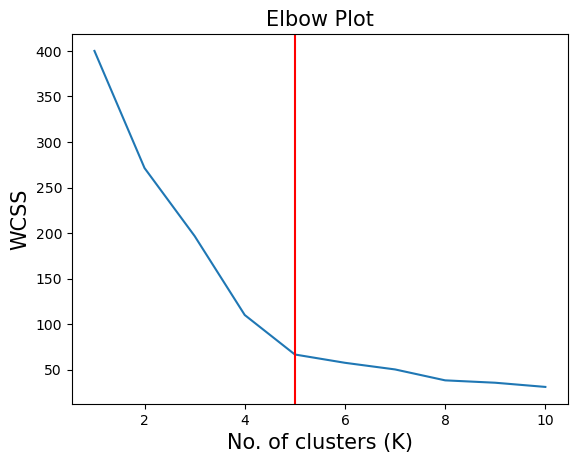

In [24]:
# visualize the elbow plot to get the optimal value of K
plt.plot(range(1,11), wcss)

# set the axes and plot labels+
# set the font size using 'fontsize'
plt.title('Elbow Plot', fontsize = 15)
plt.xlabel('No. of clusters (K)', fontsize = 15)
plt.ylabel('WCSS', fontsize = 15)
plt.axvline(x = 5, color = 'red')


# display the plot
plt.show()

##### Optimal K Value Using Silhouette Score 

The Silhouette score can also be used to identify the optimal number of clusters. We plot the Silhouette score for different values of K. The `K` with the highest Silhouette score represents the optimal value for the number of clusters (K).

Each bar in the silhouette plot represents one sample’s silhouette coefficient, which ranges from –1 to +1.

+1 → Perfectly matched to its cluster

0 → On the border between clusters

–1 → Possibly assigned to the wrong cluster

The average silhouette score (red dashed line) indicates the overall clustering quality.

In [25]:
n_clusters = [2, 3, 4, 5, 6]
for K in n_clusters:
    cluster = KMeans (n_clusters= K, random_state= 10)
    predict = cluster.fit_predict(X)
    score = silhouette_score(X, predict, random_state= 10)
    print ("For {} clusters the silhouette score is {})".format(K, score))

For 2 clusters the silhouette score is 0.3512416304427518)
For 3 clusters the silhouette score is 0.34050134194775034)
For 4 clusters the silhouette score is 0.4909821066909295)
For 5 clusters the silhouette score is 0.5520621436353863)
For 6 clusters the silhouette score is 0.5435927119668869)


##### Silhouette Visualizer
Silhouette Visualizer is a graphical tool provided by the Yellowbrick library that helps evaluate the quality of a clustering model by visualizing how well each data point fits within its assigned cluster compared to other clusters.

Each bar in the silhouette plot represents one sample’s silhouette coefficient, which ranges from –1 to +1.

+1 → Perfectly matched to its cluster

0 → On the border between clusters

–1 → Possibly assigned to the wrong cluster

The average silhouette score (red dashed line) indicates the overall clustering quality.

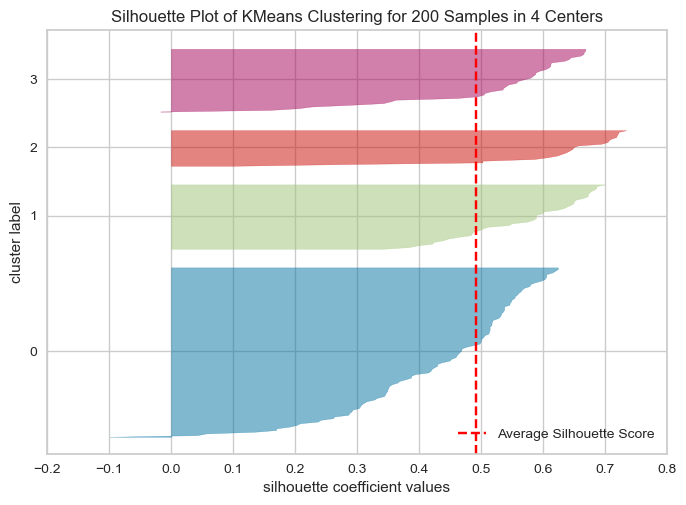

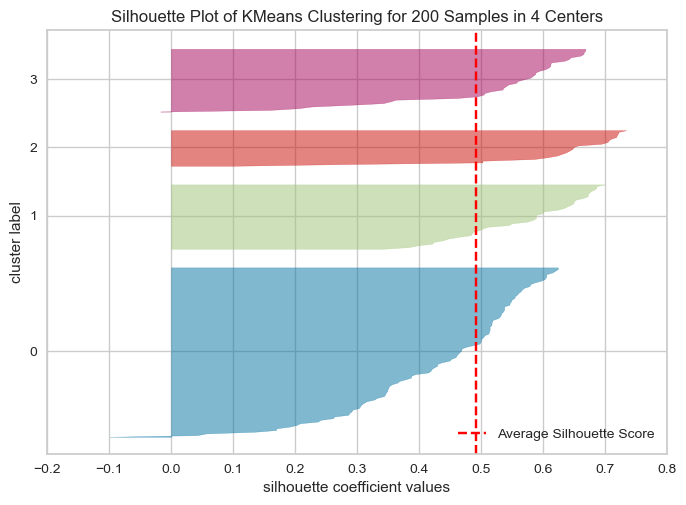

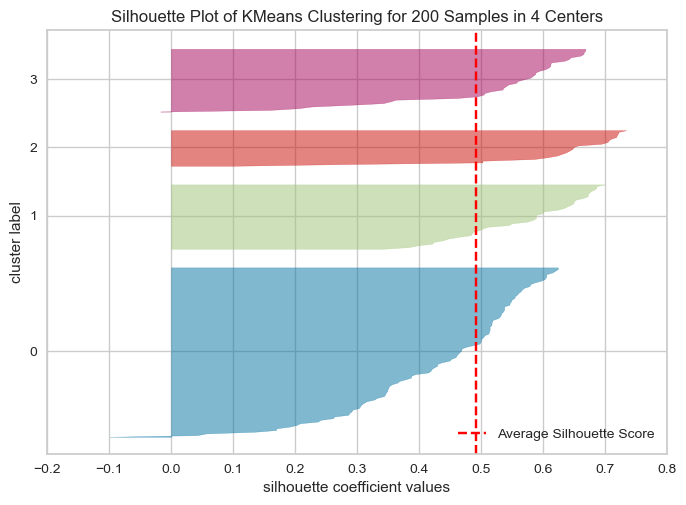

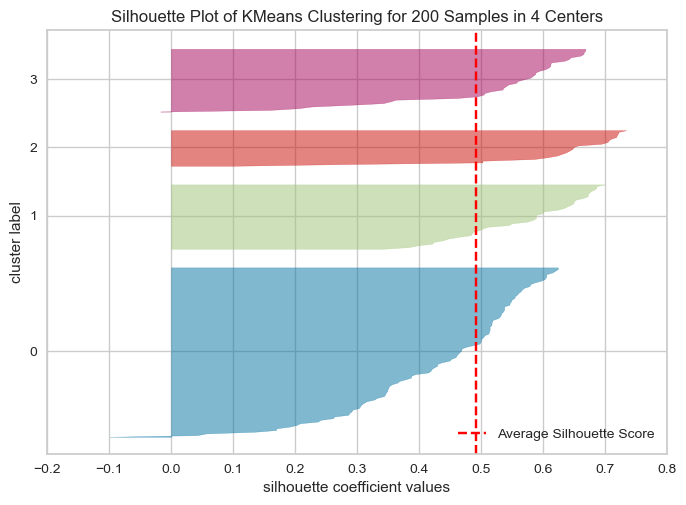

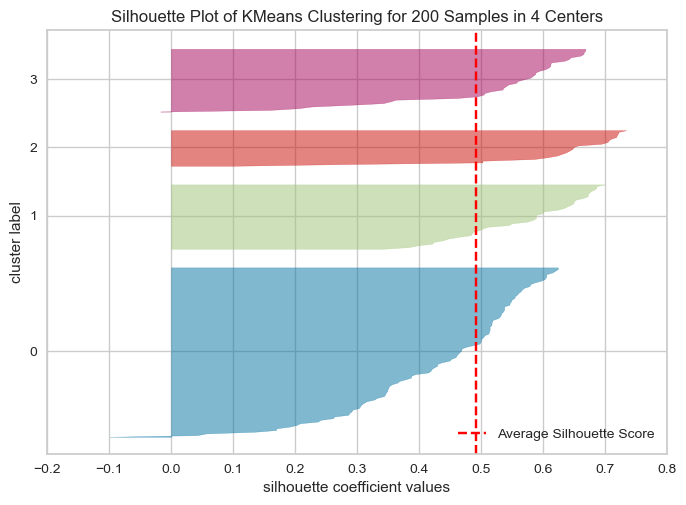

In [65]:
from yellowbrick.cluster import SilhouetteVisualizer

n_clusters = [2, 3, 4, 5, 6]
for K in n_clusters:
    model = KMeans(n_clusters=4, random_state=42)
    visualizer = SilhouetteVisualizer(model, colors='yellowbrick')
    visualizer.fit(X)
    visualizer.show()


###### Build the KMeans Model with optimal k value

In [26]:
kmeans = KMeans(n_clusters = 5, random_state = 10)
kmeans.fit(X)
X['Cluster'] = kmeans.labels_

###### Cluster Evaluation

In [27]:
X['Cluster'].head()

0    2
1    3
2    2
3    3
4    2
Name: Cluster, dtype: int32

<Axes: xlabel='Cust_Spend_Score', ylabel='Yearly_Income'>

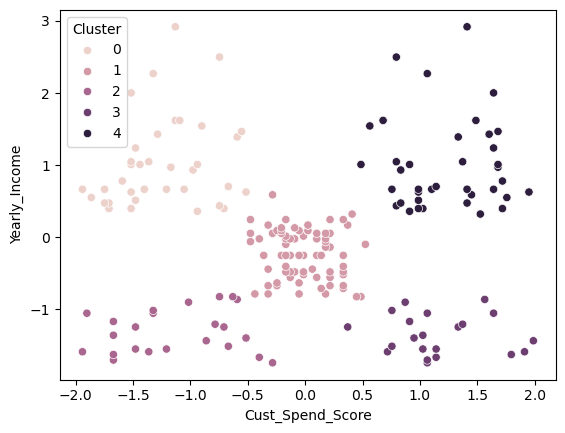

In [28]:
sns.scatterplot(x=X['Cust_Spend_Score'],y=X['Yearly_Income'],hue=X['Cluster'])

##### Hierarchical Clustering

Hierarchical Clustering is an unsupervised learning technique that groups data into a hierarchy or tree-like structure of clusters.
It either merges smaller clusters into larger ones (agglomerative approach) or divides a large cluster into smaller ones (divisive approach) until all data points are organized in a hierarchy.

In simple words: Hierarchical Clustering builds a tree of clusters, showing how data points are grouped together step by step.

In [29]:
from sklearn.cluster import AgglomerativeClustering

###### Agglomerative Clustering

Agglomerative Clustering is the most common type of hierarchical clustering.
It starts by treating each data point as a single cluster and then repeatedly merges the two closest clusters until all points belong to one big cluster or a desired number of clusters is formed.

In simple words:
Agglomerative Clustering starts with individual points and keeps joining the nearest pairs of clusters step by step.

###### Agglomarative Model

In [34]:
from sklearn.cluster import AgglomerativeClustering
agg_cluster = AgglomerativeClustering(n_clusters=5, linkage='ward')
X['labels'] = agg_cluster.fit_predict(X)

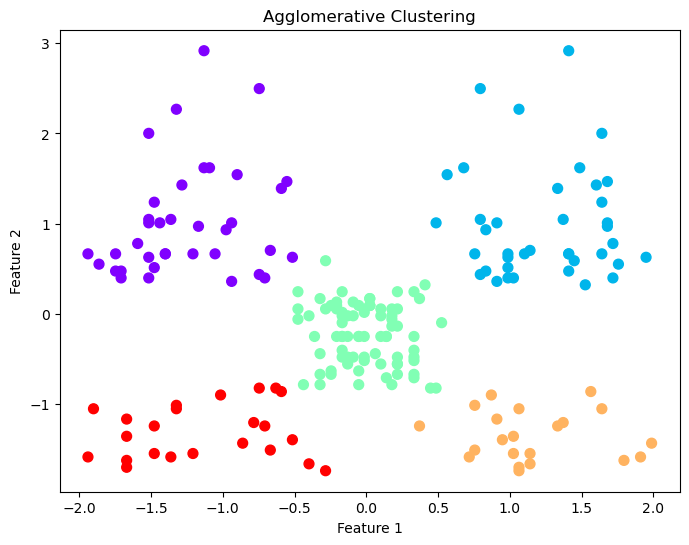

In [35]:
plt.figure(figsize=(8,6))
plt.scatter(X['Cust_Spend_Score'],X['Yearly_Income'], c=X['labels'], cmap='rainbow', s=50)
plt.title("Agglomerative Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

###### Cluster Evaluation

In [36]:
X['labels'].value_counts()

labels
2    80
1    39
0    37
4    23
3    21
Name: count, dtype: int64

###### Dendrogram

In [38]:
from scipy.cluster.hierarchy import linkage
from scipy.cluster.hierarchy import dendrogram

In [40]:
link_mat = linkage(X, method = 'ward')

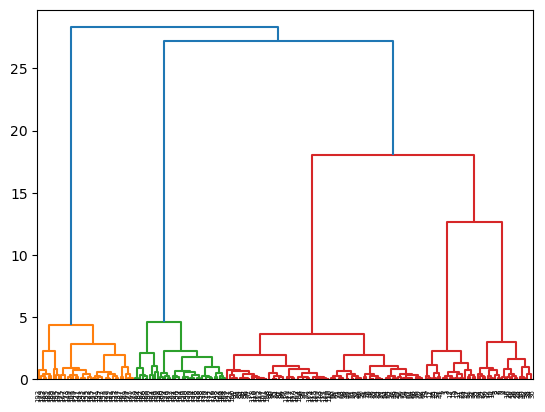

In [42]:
dendrogram(link_mat)
plt.show()

###### Silhouette Score 

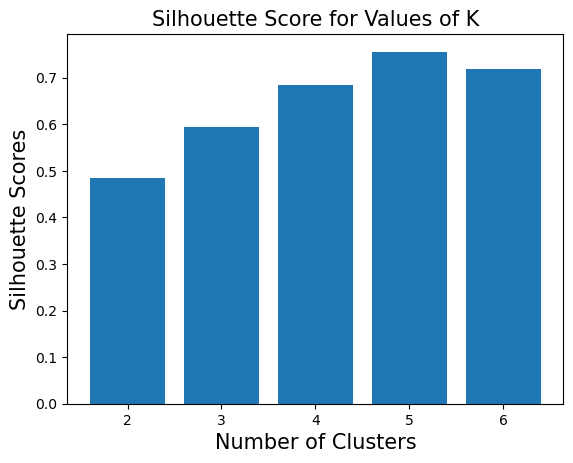

[np.float64(0.4836722443607161), np.float64(0.593893409975091), np.float64(0.6845026539010834), np.float64(0.7558387551251957), np.float64(0.7183886488395089)]


In [47]:
# consider different values of K
K = [2,3,4,5,6]
# consider an empty list tot store the Silhouette score
silhouette_scores = [] 
# consider a for loop to perform clustering for different values of K
for i in K:
    model = AgglomerativeClustering(n_clusters = i) 
    silhouette_scores.append(silhouette_score(X, model.fit_predict(X))) 
plt.bar(K, silhouette_scores) 

plt.title('Silhouette Score for Values of K', fontsize = 15)
plt.xlabel('Number of Clusters', fontsize = 15) 
plt.ylabel('Silhouette Scores', fontsize = 15)

# display the plot
plt.show()

print(silhouette_scores)

##### DBSCAN (Density-Based Spatial Clustering of Applications with Noise)

Definition:
DBSCAN is a density-based clustering algorithm that groups together points that are closely packed (dense regions) and marks points in low-density areas as outliers (noise).
It does not require specifying the number of clusters in advance.

###### DBSCAN Model

In [66]:
from sklearn.cluster import DBSCAN

In [70]:
dbscan = DBSCAN(eps=0.5, min_samples=5)  # you can tune these values
X['db_labels'] = dbscan.fit_predict(X)

In [71]:
X['db_labels'].value_counts()

db_labels
 0    188
-1     12
Name: count, dtype: int64

#### Dimensionality Reduction Technique

Dimensionality Reduction is a technique used in machine learning and data analysis to reduce the number of input variables (features) in a dataset while keeping the most important information.
It helps simplify models, improve performance, and remove redundant or less informative features.

In simple words:
Dimensionality Reduction means reducing the number of features in the data but keeping the most meaningful patterns.

#### Problem Statement

The HR department of an MNC in New York collects information about their employees. The department records the age, monthly income, total experience and information about the employee's professional work. The department uses this data to find which employees might undergo attrition. There are various factors affecting the attrition of an employee. We can use various dimension reduction techniques to analyze the higher dimensional dataset more effectively. 

####  Data Dictionary (Employee attrition data)

**Age**: Age of the employee

**DailyRate**: Per day rate of the employee

**DistanceFromHome**: Distance between the office and the employee's home 

**HourlyRate**: Per hour rate of the employee

**MonthlyIncome**: Monthly salary of the employee

**MonthlyRate**: Monthly rate of the employee

**NumCompaniesWorked**: Total number of companies in which the employee worked

**PercentSalaryHike**: Percent increase in salary

**TotalWorkingYears**: Total experience (in years)

**TrainingTimesLastYear**: Number of times the employee undergo the training program in the previous year

**YearsAtCompany**: Number of years the employee has worked with the company

**YearsInCurrentRole**: Number of years in the current role

**YearsSinceLastPromotion**: Number of years since the last promotion

**YearsWithCurrManager**: Number of years with the current manager

**Attrition**: Employee leaving the company (1=Yes or 0=No) (target/dependent variable)

##### PCA (Principal Component Analysis)

Principal Component Analysis (PCA) is a statistical technique used for dimensionality reduction that transforms the original correlated features into a new set of uncorrelated variables called principal components.
These components capture the maximum variance (information) in the data using fewer dimensions.

In simple words:
PCA finds new axes (directions) in the data that explain most of the variation and uses them to represent the data with fewer features.

##### PCA Model

In [25]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report

In [26]:
df = pd.read_csv('attrition.csv')
df.head()

,Age,DailyRate,DistanceFromHome,HourlyRate,MonthlyIncome,MonthlyRate,NumCompaniesWorked,PercentSalaryHike,TotalWorkingYears,TrainingTimesLastYear,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Attrition
0,53,124,2,38,7525,23537,2,12,30,2,15,7,6,12,0
1,21,337,7,31,2679,4567,1,13,1,3,1,0,1,0,1
2,36,1218,9,82,3407,6986,7,23,10,4,5,3,0,3,1
3,38,1391,10,66,2684,12127,0,17,3,0,2,1,0,2,0
4,24,1476,4,42,4162,15211,1,12,5,3,5,4,0,3,0


In [4]:
df.shape

(2233, 15)

In [6]:
df.dtypes

Age                        int64
DailyRate                  int64
DistanceFromHome           int64
HourlyRate                 int64
MonthlyIncome              int64
MonthlyRate                int64
NumCompaniesWorked         int64
PercentSalaryHike          int64
TotalWorkingYears          int64
TrainingTimesLastYear      int64
YearsAtCompany             int64
YearsInCurrentRole         int64
YearsSinceLastPromotion    int64
YearsWithCurrManager       int64
Attrition                  int64
dtype: object

In [7]:
df.isnull().sum()

Age                        0
DailyRate                  0
DistanceFromHome           0
HourlyRate                 0
MonthlyIncome              0
MonthlyRate                0
NumCompaniesWorked         0
PercentSalaryHike          0
TotalWorkingYears          0
TrainingTimesLastYear      0
YearsAtCompany             0
YearsInCurrentRole         0
YearsSinceLastPromotion    0
YearsWithCurrManager       0
Attrition                  0
dtype: int64

In [9]:
# Split the Data

In [10]:
X = df.drop(columns='Attrition')
y = df[['Attrition']]
Xtrain, Xtest, ytrain, ytest = train_test_split(X, y, test_size=0.2, random_state=42)


In [11]:
# Scale the Data 

In [14]:
SS = StandardScaler()
scaled_xtrain = SS.fit_transform(Xtrain)
scaled_xtrain = pd.DataFrame(scaled_xtrain,columns=Xtrain.columns)
scaled_xtest = SS.transform(Xtest)
scaled_xtest = pd.DataFrame(scaled_xtest,columns=Xtest.columns)

In [18]:
pca = PCA(n_components=8,random_state=10)
X_train_pca = pca.fit_transform(scaled_xtrain)
X_test_pca = pca.transform(scaled_xtest)

In [19]:
# Explained Variance

In [20]:
pca.explained_variance_ratio_.sum()

np.float64(0.8452534946910656)

In [22]:
#### Decision Tree Algorithm

In [24]:
DT_pca = DecisionTreeClassifier()
DT_pca_model = DT_pca.fit(X_train_pca,ytrain)
DT_pca_pred = DT_pca_model.predict(X_test_pca)

##### PCA Model Evaluation

In [31]:
print(classification_report(ytest,DT_pca_pred))

              precision    recall  f1-score   support

           0       0.99      0.79      0.88       256
           1       0.78      0.98      0.87       191

    accuracy                           0.87       447
   macro avg       0.88      0.89      0.87       447
weighted avg       0.90      0.87      0.88       447



##### Model Without PCA data

In [29]:
DT_normal = DecisionTreeClassifier()
DT_normal_model = DT_pca.fit(scaled_xtrain,ytrain)
DT_normal_pred = DT_pca_model.predict(scaled_xtest)

In [32]:
print(classification_report(ytest,DT_normal_pred))

              precision    recall  f1-score   support

           0       0.99      0.83      0.90       256
           1       0.81      0.98      0.89       191

    accuracy                           0.90       447
   macro avg       0.90      0.91      0.90       447
weighted avg       0.91      0.90      0.90       447



###### We can clearly see that the model performance has not decrease a lot by reducing the independent variables. This reduction in Independent variables has brought the model to a lower dimension model without lossong much of score

##### Association Rule Learning

Association Rule Learning is an unsupervised machine learning technique used to find hidden relationships or patterns between variables in large datasets.
It helps identify how the occurrence of one item is associated with another.

In simple words:
It finds “if–then” relationships in data — for example, “If a customer buys bread, they are likely to buy butter.

##### Apriori Algorithm:

The Apriori Algorithm is a fundamental algorithm used in association rule learning to identify frequent itemsets in large datasets.
It works by using the “Apriori property”, which states that if an itemset is frequent, then all of its subsets must also be frequent.

In simple words:
Apriori helps find which items often appear together and then builds association rules from them.

Example:
Using Apriori to discover that {Milk, Bread} → {Butter} appears frequently in transaction data.

In [3]:
# Import libraries
import pandas as pd
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

In [1]:
# 1. Sample Transaction Dataset
transactions = [
    ['Milk', 'Bread', 'Eggs'],
    ['Milk', 'Bread'],
    ['Milk', 'Eggs'],
    ['Bread', 'Butter'],
    ['Milk', 'Butter'],
    ['Bread', 'Eggs'],
]

In [14]:
# 2. Convert transaction list to One-Hot Encoded DF

te = TransactionEncoder()
te_array = te.fit_transform(transactions)
df = pd.DataFrame(te_array, columns=te.columns_)

print("One-Hot Encoded Data:")
print(df)

One-Hot Encoded Data:
   Bread  Butter   Eggs   Milk
0   True   False   True   True
1   True   False  False   True
2  False   False   True   True
3   True    True  False  False
4  False    True  False   True
5   True   False   True  False


In [16]:
# 3. Frequent Itemsets (Apriori)
# -------------------------
frequent_items = apriori(df, min_support=0.3, use_colnames=True)
print("\nFrequent Itemsets:")
print(frequent_items)


Frequent Itemsets:
    support       itemsets
0  0.666667        (Bread)
1  0.333333       (Butter)
2  0.500000         (Eggs)
3  0.666667         (Milk)
4  0.333333  (Eggs, Bread)
5  0.333333  (Milk, Bread)
6  0.333333   (Milk, Eggs)


In [17]:
# 4. Association Rules

rules = association_rules(frequent_items, metric="confidence", min_threshold=0.5)

print("\nAssociation Rules:")
print(rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']])



Association Rules:
  antecedents consequents   support  confidence  lift
0      (Eggs)     (Bread)  0.333333    0.666667  1.00
1     (Bread)      (Eggs)  0.333333    0.500000  1.00
2      (Milk)     (Bread)  0.333333    0.500000  0.75
3     (Bread)      (Milk)  0.333333    0.500000  0.75
4      (Milk)      (Eggs)  0.333333    0.500000  1.00
5      (Eggs)      (Milk)  0.333333    0.666667  1.00


##### Market Basket Analysis: 

Market Basket Analysis is an application of association rule learning that studies the co-occurrence of products in customer transactions.
It helps retailers understand which items are frequently bought together and improve product placement, cross-selling, and promotions.

In simple words:
Market Basket Analysis finds products that are often purchased together in the same shopping basket.

In [14]:
transactions = [
    ['Milk', 'Egg', 'Bread', 'Butter'], 
    ['Milk', 'Butter', 'Egg', 'Ketchup'],
    ['Bread', 'Butter', 'Ketchup'],
    ['Milk', 'Bread', 'Butter'], 
    ['Bread', 'Butter', 'Cookies'], 
    ['Milk', 'Bread', 'Butter','Cookies'], 2
    ['Milk','Cookies'],
    ['Milk', 'Bread', 'Butter'], 
    ['Bread', 'Butter', 'Egg', 'Cookies'], 
    ['Milk', 'Butter', 'Bread'],
    ['Milk', 'Bread', 'Butter'], 
    ['Milk', 'Bread', 'Cookies', 'Ketchup'] 1
]

In [15]:
te = TransactionEncoder()
te_array = te.fit_transform(transactions)
df = pd.DataFrame(te_array, columns=te.columns_)

print("One-Hot Encoded Data:")
print(df)

One-Hot Encoded Data:
    Bread  Butter  Cookies    Egg  Ketchup   Milk
0    True    True    False   True    False   True
1   False    True    False   True     True   True
2    True    True    False  False     True  False
3    True    True    False  False    False   True
4    True    True     True  False    False  False
5    True    True     True  False    False   True
6   False   False     True  False    False   True
7    True    True    False  False    False   True
8    True    True     True   True    False  False
9    True    True    False  False    False   True
10   True    True    False  False    False   True
11   True   False     True  False     True   True


In [39]:
frequent_items = apriori(df, min_support=0.05, use_colnames=True)
print("\nFrequent Itemsets:")
print(frequent_items)


Frequent Itemsets:
     support                         itemsets
0   0.833333                          (Bread)
1   0.833333                         (Butter)
2   0.416667                        (Cookies)
3   0.250000                            (Egg)
4   0.250000                        (Ketchup)
5   0.750000                           (Milk)
6   0.750000                  (Butter, Bread)
7   0.333333                 (Cookies, Bread)
8   0.166667                     (Egg, Bread)
9   0.166667                 (Ketchup, Bread)
10  0.583333                    (Milk, Bread)
11  0.250000                (Cookies, Butter)
12  0.250000                    (Butter, Egg)
13  0.166667                (Ketchup, Butter)
14  0.583333                   (Milk, Butter)
15  0.083333                   (Cookies, Egg)
16  0.083333               (Cookies, Ketchup)
17  0.250000                  (Cookies, Milk)
18  0.083333                   (Ketchup, Egg)
19  0.166667                      (Milk, Egg)
20  0.166667  

In [31]:
3/12

0.25

In [6]:
# 4. Association Rules

rules = association_rules(frequent_items, metric="confidence", min_threshold=0.5)

print("\nAssociation Rules:")
print(rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']])



Association Rules:
        antecedents      consequents   support  confidence      lift
0          (Butter)          (Bread)  0.750000    1.000000  1.200000
1           (Bread)         (Butter)  0.750000    0.900000  1.200000
2         (Cookies)          (Bread)  0.333333    0.800000  0.960000
3            (Milk)          (Bread)  0.583333    0.777778  0.933333
4           (Bread)           (Milk)  0.583333    0.700000  0.933333
5            (Milk)         (Butter)  0.500000    0.666667  0.888889
6          (Butter)           (Milk)  0.500000    0.666667  0.888889
7    (Milk, Butter)          (Bread)  0.500000    1.000000  1.200000
8     (Milk, Bread)         (Butter)  0.500000    0.857143  1.142857
9   (Butter, Bread)           (Milk)  0.500000    0.666667  0.888889
10           (Milk)  (Butter, Bread)  0.500000    0.666667  0.888889
11         (Butter)    (Milk, Bread)  0.500000    0.666667  1.142857
12          (Bread)   (Milk, Butter)  0.500000    0.600000  1.200000


##### Recommendation Systems

A Recommendation System is a machine learning application that predicts and suggests items a user may like based on their past behavior, preferences, or similarity to other users or items.
These systems are widely used in e-commerce, streaming platforms, and online services.

In simple words:
Recommendation Systems help users discover new items they’re likely to be interested in — like movies, songs, or products.

##### Collaborative Filtering

Collaborative Filtering is a recommendation technique that makes predictions based on the behavior and preferences of many users.
It assumes that users with similar tastes in the past will have similar preferences in the future.

In simple words:
Collaborative Filtering recommends an item to a user by finding other users or items that are similar.

Two main types:

User-Based Collaborative Filtering – finds users similar to the target user and recommends items they liked.

Item-Based Collaborative Filtering – finds items similar to what the user liked and recommends them.

In [22]:
# create a new env in anaconda prompt 
# than install surprise package in it 
# than integrate it with jupyter notebook 


#Run these commands in Anaconda Prompt.
create -n recommender_env python=3.10
activate recommender_env 
conda install -c conda-forge scikit-surprise
install surprise
conda install ipykernel 
python -m ipykernel install --user --name recommender_env --display-name 'recommended_env'

In [5]:
import pandas as pd
from surprise import Dataset, Reader, KNNBasic

In [3]:
#!pip install pandas 

In [6]:
#!pip install surprise

In [9]:
ratings_dict = {
    'userID': ['A', 'A', 'A',  # User A (Missing Item 4)
               'B', 'B', 'B', 'B',
               'C', 'C', 'C', 'C',
               'D', 'D', 'D', 'D'],
    'itemID': ['I1', 'I2', 'I3', 
               'I1', 'I2', 'I3', 'I4',
               'I1', 'I2', 'I3', 'I4',
               'I1', 'I2', 'I3', 'I4'],
    'rating': [4, 3, 5,        
               5, 5, 4, 3,
               4, 3, 5, 3,
               2, 4, 2, 3]
}
df = pd.DataFrame(ratings_dict)
df.head(2)

,userID,itemID,rating
0,A,I1,4
1,A,I2,3


In [12]:
# Tell Surprise the range of your ratings (e.g., 1 to 5 stars)
reader = Reader(rating_scale=(1, 5))

In [14]:
# Load the data
data = Dataset.load_from_df(df[['userID', 'itemID', 'rating']], reader)
trainset = data.build_full_trainset()
trainset

In [15]:
# 2. USER-BASED FILTERING
# ==========================================
print("--- USER-BASED RESULT ---")
# Configuration: Use Cosine similarity, and user_based=True
sim_options_user = {
    'name': 'cosine',
    'user_based': True  # <--- This makes it User-Based
}

--- USER-BASED RESULT ---


In [16]:
# KNNBasic is the standard algorithm for Collaborative Filtering
algo_user = KNNBasic(sim_options=sim_options_user)
algo_user.fit(trainset)


Computing the cosine similarity matrix...
Done computing similarity matrix.


In [18]:
# Predict User A on Item I4
pred_user = algo_user.predict(uid='A', iid='I4')
print(f"Prediction: {pred_user.est:.4f}")

Prediction: 3.0000


In [19]:
# 3. ITEM-BASED FILTERING
# ==========================================
print("\n--- ITEM-BASED RESULT ---")
# Configuration: Use Cosine similarity, and user_based=False
sim_options_item = {
    'name': 'cosine',
    'user_based': False  # <--- This makes it Item-Based
}



--- ITEM-BASED RESULT ---


In [20]:
algo_item = KNNBasic(sim_options=sim_options_item)
algo_item.fit(trainset)


Computing the cosine similarity matrix...
Done computing similarity matrix.


In [21]:
# Predict User A on Item I4
pred_item = algo_item.predict(uid='A', iid='I4')
print(f"Prediction: {pred_item.est:.4f}")

Prediction: 3.9885
